In [296]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("visuals", exist_ok=True)

**Loading the dataset**

In [10]:
df=pd.read_csv("C:\\Users\\Saurabh\\OneDrive\\Desktop\\Subscripption data project using pandas\\subscription_data.csv")
df

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
0,10001,56.0,Female,Chennai,12/3/2022,12/29/2022,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90
1,10002,46.0,Female,Mumbai,3/24/2021,1/25/2022,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40
2,10003,32.0,Female,Mumbai,6/15/2023,8/10/2023,Basic,783,4,0,41.93,5.0,Referral,No,3092.85
3,10004,60.0,Male,Delhi,11/13/2022,7/8/2021,Standard,545,4,1,116.41,0.0,Organic,No,2180.00
4,10005,25.0,Female,Mumbai,2/17/2022,6/25/2021,Basic,1331,30,1,81.89,10.0,Ads,No,39796.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2555,11315,61.0,Male,Bangalore,11/17/2021,10/15/2022,Basic,1194,17,1,78.57,20.0,Organic,No,20059.20
2556,10645,25.0,Female,Pune,1/15/2022,11/3/2023,Basic,1016,18,2,9.21,NaN,Email,No,18288.00
2557,12103,25.0,Female,Chennai,1/21/2022,8/14/2022,Premium,801,20,1,11.67,20.0,Organic,No,15859.80
2558,10615,NaN,Female,Pune,3/17/2022,10/7/2023,Premium,692,22,0,34.42,0.0,Ads,No,15224.00


In [57]:
# Checking the data type of each column
# --> signup_date ="str"
# -->last_active_date="str"
df.dtypes

customer_id                        int64
age                              float64
gender                               str
city                                 str
signup_date               datetime64[us]
last_active_date          datetime64[us]
plan_type                            str
monthly_fee                        int64
tenure_months                      int64
support_tickets                    int64
avg_session_time                 float64
discount_percent                 float64
marketing_channel                    str
churned                              str
total_revenue                    float64
tenure_years                     float64
revenue_per_month                float64
binary_churn                         str
age_group                       category
high_value_customer                  str
days_since_last_active             int64
dtype: object

In [59]:
# knowing the information of the data
df.info()

<class 'pandas.DataFrame'>
Index: 1648 entries, 0 to 2499
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_id             1648 non-null   int64         
 1   age                     1648 non-null   float64       
 2   gender                  1648 non-null   str           
 3   city                    1648 non-null   str           
 4   signup_date             1648 non-null   datetime64[us]
 5   last_active_date        1648 non-null   datetime64[us]
 6   plan_type               1648 non-null   str           
 7   monthly_fee             1648 non-null   int64         
 8   tenure_months           1648 non-null   int64         
 9   support_tickets         1648 non-null   int64         
 10  avg_session_time        1648 non-null   float64       
 11  discount_percent        1648 non-null   float64       
 12  marketing_channel       1648 non-null   str           
 13  chur

In [61]:
# Checking the top records
df.head(10)

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,discount_percent,marketing_channel,churned,total_revenue,tenure_years,revenue_per_month,binary_churn,age_group,high_value_customer,days_since_last_active
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,15.0,Referral,Yes,30167.90,2.083333,1206.716000,1,Senior,Yes,1417
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,20.0,Organic,Yes,27642.40,1.833333,1256.472727,1,Senior,Yes,1755
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,5.0,Referral,No,3092.85,0.333333,773.212500,0,Middle,No,1193
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,15.0,Email,No,834.35,0.166667,417.175000,0,Middle,No,1584
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,15.0,Organic,No,13886.10,1.750000,661.242857,0,Middle,Yes,1423
9,10010,28.0,Male,Chennai,2021-08-17,2022-05-23,Basic,385,21,4,...,15.0,Email,No,8027.25,1.750000,382.250000,0,Middle,No,1637
11,10012,41.0,Male,Delhi,2022-01-02,2023-08-18,Standard,745,1,4,...,20.0,Email,No,596.00,0.083333,596.000000,0,Middle,No,1185
17,10018,19.0,Male,Delhi,2022-06-08,2022-08-07,Standard,346,25,1,...,5.0,Email,No,8632.70,2.083333,345.308000,0,Young,No,1561
18,10019,41.0,Male,Delhi,2021-03-13,2022-08-05,Standard,1056,26,1,...,5.0,Ads,No,27403.20,2.166667,1053.969231,0,Middle,Yes,1563
20,10021,47.0,Female,Mumbai,2021-04-16,2022-12-29,Premium,1347,3,2,...,20.0,Referral,No,3771.60,0.250000,1257.200000,0,Senior,No,1417


In [63]:
# checking the bottom records
df.tail(10)

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,discount_percent,marketing_channel,churned,total_revenue,tenure_years,revenue_per_month,binary_churn,age_group,high_value_customer,days_since_last_active
2485,12486,23.0,Female,Chennai,2022-03-07,2022-10-29,Standard,378,4,1,...,0.0,Referral,No,1512.00,0.333333,378.000000,0,Young,No,1478
2487,12488,30.0,Female,Mumbai,2021-11-21,2022-04-18,Basic,1281,25,1,...,5.0,Email,No,31960.95,2.083333,1278.438000,0,Middle,Yes,1672
2488,12489,51.0,Male,Unknown,2022-03-18,2022-12-31,Standard,1374,23,1,...,20.0,Organic,No,31327.20,1.916667,1362.052174,0,Senior,Yes,1415
2491,12492,51.0,Other,Chennai,2021-08-14,2022-11-25,Standard,674,32,2,...,0.0,Organic,Yes,21568.00,2.666667,674.000000,1,Senior,Yes,1451
2492,12493,21.0,Male,Bangalore,2021-03-05,2023-01-07,Premium,505,23,0,...,15.0,Referral,Yes,11539.25,1.916667,501.706522,1,Young,No,1408
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,10.0,Email,No,2285.20,0.250000,761.733333,0,Middle,No,1463
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,20.0,Organic,Yes,11916.80,1.083333,916.676923,1,Young,No,1145
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,10.0,Ads,No,32623.50,2.000000,1359.312500,0,Middle,Yes,1847
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,5.0,Ads,No,790.40,0.083333,790.400000,0,Senior,No,1509
2499,12500,49.0,Male,Delhi,2021-09-14,2023-01-20,Basic,821,12,1,...,5.0,Email,Yes,9810.95,1.000000,817.579167,1,Senior,No,1395


In [65]:
# checking the no of rows and no of columns
df.shape
# rows---->2560
# columns--->15

(1648, 21)

In [67]:
# checking the statistical information of all columns
df.describe(include="all")

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,discount_percent,marketing_channel,churned,total_revenue,tenure_years,revenue_per_month,binary_churn,age_group,high_value_customer,days_since_last_active
count,1648.000000,1648.000000,1648,1648,1648,1648,1648,1648.000000,1648.000000,1648.000000,...,1648.000000,1648,1648,1648.000000,1648.000000,1648.000000,1648,1648,1648,1648.000000
unique,NaN,NaN,3,7,NaN,NaN,3,NaN,NaN,NaN,...,NaN,4,2,NaN,NaN,NaN,2,3,2,NaN
top,NaN,NaN,Female,Mumbai,NaN,NaN,Basic,NaN,NaN,NaN,...,NaN,Email,No,NaN,NaN,NaN,0,Middle,Yes,NaN
freq,NaN,NaN,806,313,NaN,NaN,721,NaN,NaN,NaN,...,NaN,450,1272,NaN,NaN,NaN,1272,712,824,NaN
mean,11255.410194,41.508495,NaN,NaN,2021-12-16 20:06:41.941747,2022-12-15 12:11:21.553398,NaN,899.979976,17.642597,2.083131,...,9.808859,NaN,NaN,15741.562955,1.470216,888.738639,NaN,NaN,NaN,1430.492112
min,10001.000000,18.000000,NaN,NaN,2021-01-01 00:00:00,2021-06-01 00:00:00,NaN,300.000000,1.000000,0.000000,...,0.000000,NaN,NaN,297.500000,0.083333,296.842105,NaN,NaN,NaN,1094.000000
25%,10632.750000,30.000000,NaN,NaN,2021-05-30 18:00:00,2022-07-15 18:00:00,NaN,593.750000,9.000000,1.000000,...,5.000000,NaN,NaN,6776.750000,0.750000,590.284712,NaN,NaN,NaN,1232.750000
50%,11265.500000,41.000000,NaN,NaN,2021-11-13 00:00:00,2023-01-20 12:00:00,NaN,901.500000,17.000000,2.000000,...,10.000000,NaN,NaN,13185.200000,1.416667,886.290909,NaN,NaN,NaN,1394.500000
75%,11873.250000,53.000000,NaN,NaN,2022-06-15 06:00:00,2023-07-01 06:00:00,NaN,1205.000000,26.000000,3.000000,...,15.000000,NaN,NaN,23225.450000,2.166667,1193.100000,NaN,NaN,NaN,1583.250000
max,12500.000000,64.000000,NaN,NaN,2023-06-15 00:00:00,2023-11-17 00:00:00,NaN,1499.000000,35.000000,8.000000,...,20.000000,NaN,NaN,50307.600000,2.916667,1497.000000,NaN,NaN,NaN,1993.000000


In [68]:
# checking the null values or missing values

# age                  105
# city                 104
# avg_session_time     101
# discount_percent     105

df.isnull().sum()

customer_id               0
age                       0
gender                    0
city                      0
signup_date               0
last_active_date          0
plan_type                 0
monthly_fee               0
tenure_months             0
support_tickets           0
avg_session_time          0
discount_percent          0
marketing_channel         0
churned                   0
total_revenue             0
tenure_years              0
revenue_per_month         0
binary_churn              0
age_group                 0
high_value_customer       0
days_since_last_active    0
dtype: int64

In [69]:
# checking the Duplicate values

df.duplicated().sum()

np.int64(0)

In [70]:
# checking the columns names

df.columns

Index(['customer_id', 'age', 'gender', 'city', 'signup_date',
       'last_active_date', 'plan_type', 'monthly_fee', 'tenure_months',
       'support_tickets', 'avg_session_time', 'discount_percent',
       'marketing_channel', 'churned', 'total_revenue', 'tenure_years',
       'revenue_per_month', 'binary_churn', 'age_group', 'high_value_customer',
       'days_since_last_active'],
      dtype='str')

## Data Cleaning 

In [71]:
# Missing value analysis
df.isnull().sum()

customer_id               0
age                       0
gender                    0
city                      0
signup_date               0
last_active_date          0
plan_type                 0
monthly_fee               0
tenure_months             0
support_tickets           0
avg_session_time          0
discount_percent          0
marketing_channel         0
churned                   0
total_revenue             0
tenure_years              0
revenue_per_month         0
binary_churn              0
age_group                 0
high_value_customer       0
days_since_last_active    0
dtype: int64

In [72]:
# Missing value % 

df.isnull().sum() /len(df)* 100

customer_id               0.0
age                       0.0
gender                    0.0
city                      0.0
signup_date               0.0
last_active_date          0.0
plan_type                 0.0
monthly_fee               0.0
tenure_months             0.0
support_tickets           0.0
avg_session_time          0.0
discount_percent          0.0
marketing_channel         0.0
churned                   0.0
total_revenue             0.0
tenure_years              0.0
revenue_per_month         0.0
binary_churn              0.0
age_group                 0.0
high_value_customer       0.0
days_since_last_active    0.0
dtype: float64

In [74]:
# Checking the duplicates 

df.duplicated().sum()

np.int64(0)

In [23]:
# Check unique values in categorical columns

df["gender"].unique()
df["city"].unique()
df["plan_type"].unique()
df["marketing_channel"].unique()
df["churned"].unique()

<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

In [24]:
# Handling the missing values
# first inspecting the numerical columns
df[["age","avg_session_time", "discount_percent"]].describe()

,age,avg_session_time,discount_percent
count,2455.000000,2459.000000,2455.000000
mean,41.155193,62.719569,10.024440
std,13.558198,32.920546,7.096911
min,18.000000,5.130000,0.000000
25%,29.000000,34.570000,5.000000
50%,41.000000,62.590000,10.000000
75%,53.000000,90.650000,15.000000
max,64.000000,119.940000,20.000000


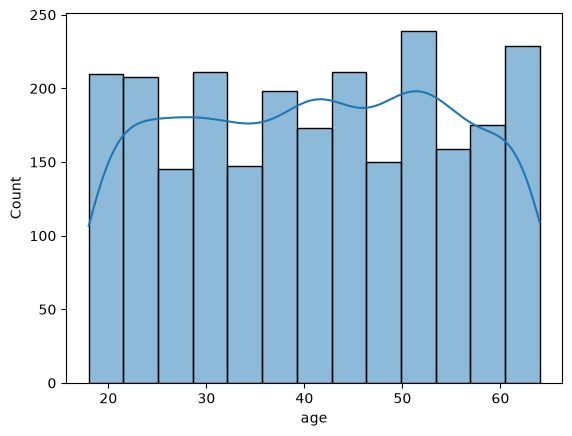

In [25]:
# Handling the missing values in age column
df["age"].isnull().value_counts()
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(df["age"],kde=True)
plt.show()

In [26]:
df["age"].mean()
df["age"].median()


np.float64(41.0)

In [27]:
# Repelacing the null values in age column

df["age"]=df["age"].fillna(41)

In [28]:
# Handling the missing values in city

df["city"].value_counts()      # To know which city has appear  most of time

# replacing the null values in city 
df["city"]=df["city"].fillna("Unknown")    

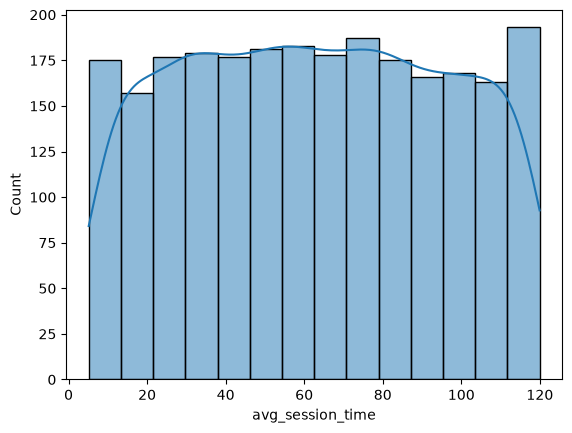

In [29]:
# Handle avg_session_time

df["avg_session_time"].median()  # median is 62.59

sns.histplot(df["avg_session_time"], kde=True)   # To check useing cbart avg time 
                                                
plt.show()

In [30]:
# Replacing avg session time with median

df["avg_session_time"] =df["avg_session_time"].fillna(62.59)

np.float64(10.0)

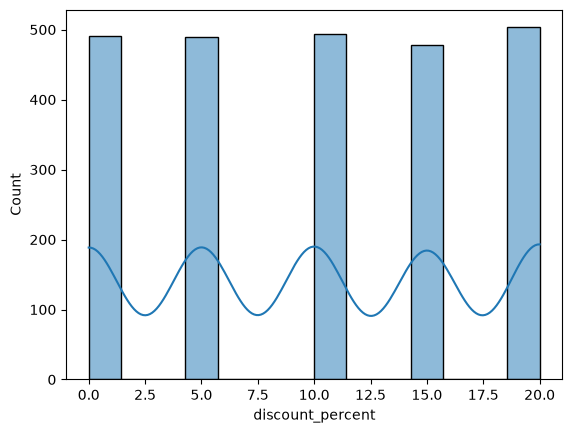

In [31]:
# Handle discount_percent

sns.histplot(df["discount_percent"],kde=True)

df["discount_percent"].median()   # Median --> 10  

In [32]:
# Replacing the discount_pct with 0
#discount is vary to different peoples
  
df["discount_percent"]=df["discount_percent"].fillna(0)

In [33]:
# Remove duplicates

df.drop_duplicates(inplace=True)       

In [34]:
# To verify the duplicates are gone or not 

df.duplicated().sum()

np.int64(0)

In [35]:
# Convert date columns in proper date datatype

df["signup_date"]=pd.to_datetime(df["signup_date"])

df["last_active_date"]=pd.to_datetime(df["last_active_date"])

In [36]:
# checking the columns name are converted or not 

df.dtypes

customer_id                   int64
age                         float64
gender                          str
city                            str
signup_date          datetime64[us]
last_active_date     datetime64[us]
plan_type                       str
monthly_fee                   int64
tenure_months                 int64
support_tickets               int64
avg_session_time            float64
discount_percent            float64
marketing_channel               str
churned                         str
total_revenue               float64
dtype: object

In [37]:
# Check illogical dates

# checking the lastest date
df["signup_date"].min()   # 2021-01-01

# checking the old date 
df["signup_date"].max()    # 2023-06-19

# checking the lastest date
df["last_active_date"].min()    # 2021-06-01

# checking the old date 
df["last_active_date"].max()   #2023-11-17


df[df["last_active_date"] < df["signup_date"]]

# Removing the illogical dates
df=df[df["last_active_date"] >= df["signup_date"]]

In [38]:
# checking the invalid dates are gone or not 

df[df["last_active_date"] < df["signup_date"]]

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue


In [39]:
# Check invalid ages

df['age'].min()    #--> 18 
   
df["age"].max()   # --> 64

df[(df["age"]<18 ) | (df["age"] > 80)]

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue


**Verifying the clean data**

In [40]:
df.dtypes     # All the dtypes are correct 


customer_id                   int64
age                         float64
gender                          str
city                            str
signup_date          datetime64[us]
last_active_date     datetime64[us]
plan_type                       str
monthly_fee                   int64
tenure_months                 int64
support_tickets               int64
avg_session_time            float64
discount_percent            float64
marketing_channel               str
churned                         str
total_revenue               float64
dtype: object

In [41]:
# checking the no of columns and no of rows

df.shape            # rows:- 1648 
                    # columns:- 15

(1648, 15)

In [42]:
# checking the null values after cleaning the data

df.isnull().sum()

customer_id          0
age                  0
gender               0
city                 0
signup_date          0
last_active_date     0
plan_type            0
monthly_fee          0
tenure_months        0
support_tickets      0
avg_session_time     0
discount_percent     0
marketing_channel    0
churned              0
total_revenue        0
dtype: int64

In [43]:
df.info()

<class 'pandas.DataFrame'>
Index: 1648 entries, 0 to 2499
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   customer_id        1648 non-null   int64         
 1   age                1648 non-null   float64       
 2   gender             1648 non-null   str           
 3   city               1648 non-null   str           
 4   signup_date        1648 non-null   datetime64[us]
 5   last_active_date   1648 non-null   datetime64[us]
 6   plan_type          1648 non-null   str           
 7   monthly_fee        1648 non-null   int64         
 8   tenure_months      1648 non-null   int64         
 9   support_tickets    1648 non-null   int64         
 10  avg_session_time   1648 non-null   float64       
 11  discount_percent   1648 non-null   float64       
 12  marketing_channel  1648 non-null   str           
 13  churned            1648 non-null   str           
 14  total_revenue      1648 

**Save the cleaned CSV**

In [44]:
df.to_csv("customer_analytics_cleaned.csv", index=False)


# Feature Engineering

In [45]:
# tenure_years
df["tenure_years"]=df["tenure_months"] / 12

In [46]:
# revenue_per_month.
df["revenue_per_month"]=df["total_revenue"] / df["tenure_months"]

In [47]:
# Create a binary churn flag (1 is Churn is “Yes”, else 0)

def churn (c):
    if c =="Yes":
        return "1"
    else:
        return "0"
df["binary_churn"]=df["churned"].apply(churn)

In [48]:
df[["churned", "binary_churn"]].head()

,churned,binary_churn
0,Yes,1
1,Yes,1
2,No,0
5,No,0
7,No,0


In [49]:
# Age Group column
# new concpt ---> pd.cut()

df["age_group"]=pd.cut(
    df['age'],
    bins=[17,25,45,80],
    labels=["Young","Middle","Senior"]
)

In [50]:
df[["age","age_group"]].head(10)

,age,age_group
0,56.0,Senior
1,46.0,Senior
2,32.0,Middle
5,38.0,Middle
7,36.0,Middle
9,28.0,Middle
11,41.0,Middle
17,19.0,Young
18,41.0,Middle
20,47.0,Senior


In [51]:
# high_value_customer
df["total_revenue"].sum() #25942095
df["total_revenue"].median() # 13185

import numpy as np
df["high_value_customer"]=np.where(

    df["total_revenue"] > df["total_revenue"].median(),
    "Yes","No"
)

In [52]:
df[["total_revenue","high_value_customer"]].head(10)

,total_revenue,high_value_customer
0,30167.90,Yes
1,27642.40,Yes
2,3092.85,No
5,834.35,No
7,13886.10,Yes
9,8027.25,No
11,596.00,No
17,8632.70,No
18,27403.20,Yes
20,3771.60,No


In [53]:
# "days_since_last_active"

df["days_since_last_active"]=(
    pd.Timestamp.today() - df["last_active_date"]
).dt.days

In [54]:
df[["last_active_date", "days_since_last_active"]].head(10)

,last_active_date,days_since_last_active
0,2022-12-29,1417
1,2022-01-25,1755
2,2023-08-10,1193
5,2022-07-15,1584
7,2022-12-23,1423
9,2022-05-23,1637
11,2023-08-18,1185
17,2022-08-07,1561
18,2022-08-05,1563
20,2022-12-29,1417


In [75]:

conditions=[

    df["avg_session_time"] < 10,
    df["avg_session_time"] <=30


]
choices=["Low","Medium"]

df["avg_session_category"]=np.select(
    conditions,
    choices,
    default="High"
)
df

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,marketing_channel,churned,total_revenue,tenure_years,revenue_per_month,binary_churn,age_group,high_value_customer,days_since_last_active,avg_session_category
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,Referral,Yes,30167.90,2.083333,1206.716000,1,Senior,Yes,1417,Medium
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,Organic,Yes,27642.40,1.833333,1256.472727,1,Senior,Yes,1755,High
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,Referral,No,3092.85,0.333333,773.212500,0,Middle,No,1193,High
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,Email,No,834.35,0.166667,417.175000,0,Middle,No,1584,High
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,Organic,No,13886.10,1.750000,661.242857,0,Middle,Yes,1423,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,Email,No,2285.20,0.250000,761.733333,0,Middle,No,1463,High
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,Organic,Yes,11916.80,1.083333,916.676923,1,Young,No,1145,High
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,Ads,No,32623.50,2.000000,1359.312500,0,Middle,Yes,1847,High
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,Ads,No,790.40,0.083333,790.400000,0,Senior,No,1509,Medium


In [ ]:
# discount_category

def category(c):
    if c == 0:
        return "No Discount"
    elif c <=10:
        return "Medium Discount"
    else:
        return "High Discount"

df["discount_category"]=df["discount_percent"].apply(category)

In [ ]:
df[["discount_percent","discount_category"]].head(5)


In [220]:
# Extracting the month name from signup date

df["month_name"]=df["signup_date"].dt.month_name()

df[["signup_date","month_name"]].head(5)

,signup_date,month_name
0,2022-12-03,December
1,2021-03-24,March
2,2023-06-15,June
5,2021-06-16,June
7,2021-06-18,June


In [221]:
# Extracting the year from signup date

df["year"]=df["signup_date"].dt.year

In [ ]:
df[["signup_date","year"]].head(10)

In [ ]:
# support_intensity
conditions=[
    df["support_tickets"]==0,
    df["support_tickets"]<=5,
    
]
choices=["low","medium"]

df["support_intensity"]=np.select(
    conditions,
    choices,
    default="High"
)


In [ ]:
# revenue category 
def rev (r):
    if r <=10000:
        return "Low"
    elif r <=30000:
        return "Medium"
    else:
        return "High"

df["revenue_category"]=df["total_revenue"].apply(rev)

In [ ]:
# Plan Rank
# map ()


df["plan_type"].unique()

plan_mapping={

    "Basic":1,
    'Premium':2,
    'Standard':3
}

df["plan_rank"] = df["plan_type"].map(plan_mapping)

In [ ]:
# 	 engagement score
df["engagement_score"]=df["avg_session_time"] / (df["support_tickets"]+1)

In [219]:
df.dtypes

customer_id                        int64
age                              float64
gender                               str
city                                 str
signup_date               datetime64[us]
last_active_date          datetime64[us]
plan_type                            str
monthly_fee                        int64
tenure_months                      int64
support_tickets                    int64
avg_session_time                 float64
discount_percent                 float64
marketing_channel                    str
churned                              str
total_revenue                    float64
tenure_years                     float64
revenue_per_month                float64
binary_churn                       int64
age_group                       category
high_value_customer                  str
days_since_last_active             int64
avg_session_category                 str
dtype: object

**Saving the file**

In [ ]:
df.to_csv("cleaned_subscription_data.csv", index=False)


# Creating Visuals 

**Customer Age Distribution**

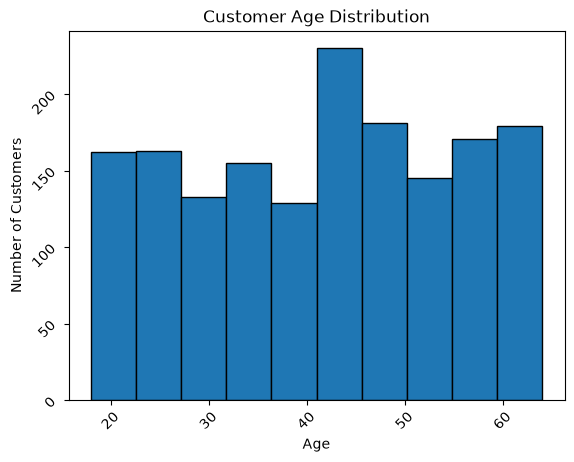

In [298]:
plt.hist(df["age"],edgecolor="black")
plt.title(" Customer Age Distribution ")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.savefig("visuals/customer_age.png", dpi=100, bbox_inches="tight")
plt.show()

In [ ]:
Observation:- The highest number of customers belongs to 41 to 45 age group

Insight:- The company can use this information and customer age range 
          then start doing marketing campign ,advertisment to attract similar customer etc

**Monthly Fee Distribution**

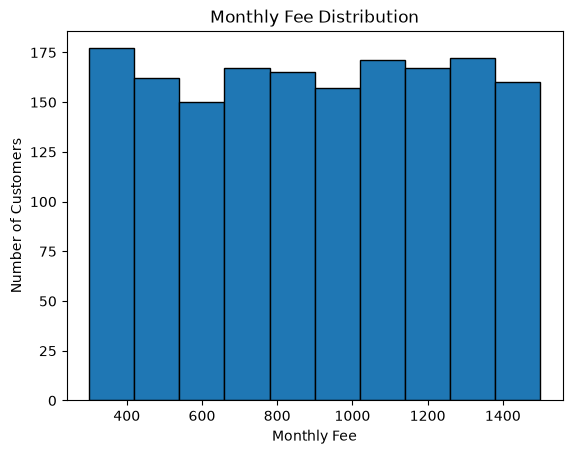

In [299]:
plt.hist(df["monthly_fee"],bins=10,edgecolor="black")
plt.xlabel("Monthly Fee")
plt.ylabel("Number of Customers")
plt.title("Monthly Fee Distribution")
plt.savefig("visuals/Monthly Fee Distributio.png", dpi=100, bbox_inches="tight")
plt.show()

In [ ]:
Observation:- The highest number of customers pay the around 400/-monthly
              subscription fees  other customers  also pay but silightly lower .

Insight:- company can identify 400 is most common subscription plan people buy often 
          because they are satisfied with that plan . so we approch to upgrade their plan.

**Revenue Distribution**

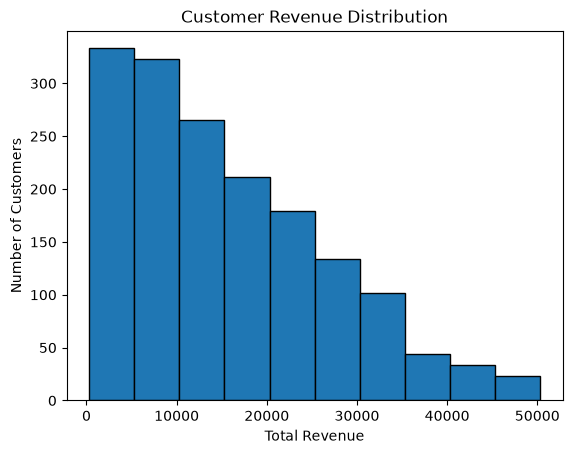

In [300]:
plt.hist(df["total_revenue"], bins=10,edgecolor="black")

plt.xlabel("Total Revenue")
plt.ylabel("Number of Customers")
plt.title("Customer Revenue Distribution")
plt.savefig("visuals/Customer Revenue Distribution.png", dpi=100, bbox_inches="tight")
plt.show()

In [ ]:
Observaation:- the higher revenue is increasing the num  of cust decreasing and also 
                very few cust are generate the higher revenue.

insight:-  company can focous more on stratergies and focus on
            improving low cust - middle cust retaination through suitable plans.

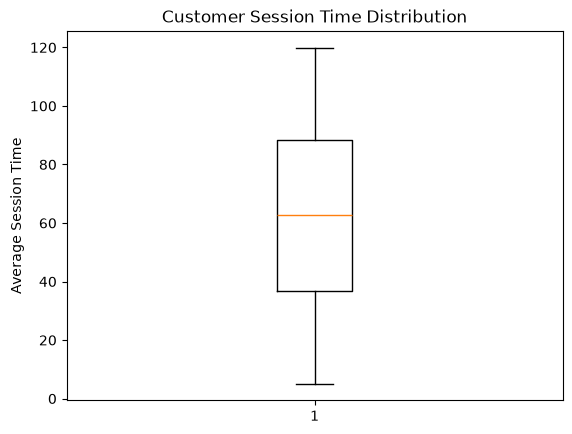

In [301]:
#  Avg Session Time Distribution
plt.boxplot(df["avg_session_time"])

plt.ylabel("Average Session Time")
plt.title("Customer Session Time Distribution")
plt.savefig("visuals/Customer Session Time Distribution.png", dpi=100, bbox_inches="tight")
plt.show()

In [ ]:
Observation:- we can see orange line in the middle of boxplot which shows the median , there is  no 
              any outlier present in this chart

Insights= company can use this information of avg session time ,understand pattern and improve the 
          platform use to bring the attension of customers 

**Revenue by Plan Type**

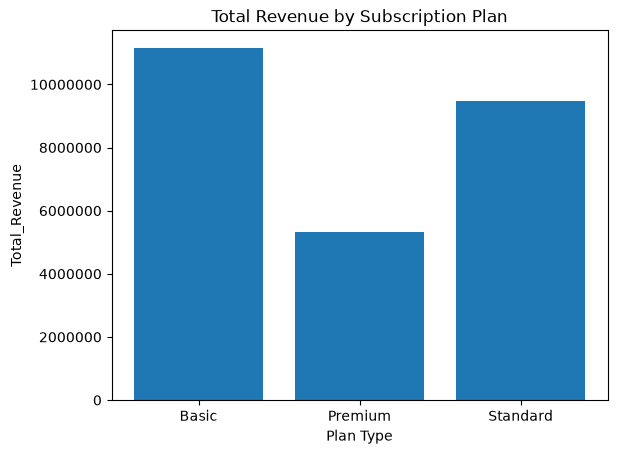

In [302]:
plan_revenue=df.groupby("plan_type") ["total_revenue"].sum()

plt.bar(plan_revenue.index,plan_revenue.values)
plt.xlabel("Plan Type")
plt.ylabel("Total_Revenue")
plt.title("Total Revenue by Subscription Plan")
plt.ticklabel_format(axis='y', style='plain')
plt.savefig("visuals/Total Revenue by Subscription Plan.png", dpi=100, bbox_inches="tight")

plt.show()

In [ ]:
Observation:- The basic plan generates the highest revenue ,followed by standard plan also but premium
              plan type is generating the lower revenue than others 

Insights:-  the companay can more focous on basic plan bcz it generates more revenue also improve  the
            more features and encourage the  customer to buy standard and premium plans and most important
            to identify what make basic plan that attractive to  more customers attract.
            

**Churn Rate By Plan Type**

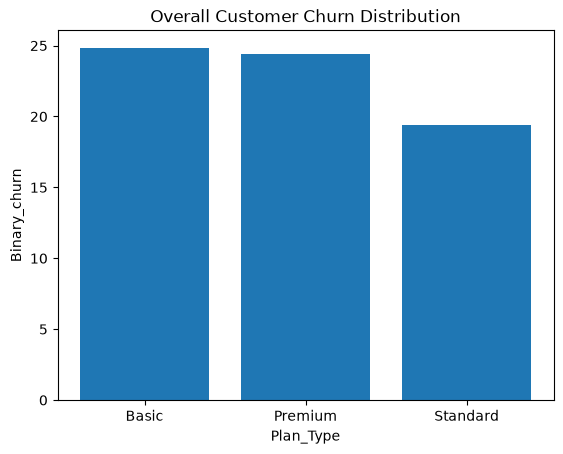

plan_type
Basic       24.826630
Premium     24.411765
Standard    19.420784
Name: binary_churn, dtype: float64

In [303]:
# mean() * 100 calculates the percentage of customers who churned in each plan.

churn_rate=df.groupby("plan_type") ["binary_churn"].mean() *100
 
churn_rate

plt.bar(churn_rate.index,churn_rate.values)


plt.title("Overall Customer Churn Distribution")
plt.xlabel("Plan_Type")
plt.ylabel("Binary_churn")
plt.savefig("visuals/Overall Customer Churn Distribution.png", dpi=100, bbox_inches="tight")

plt.show()
churn_rate

In [ ]:
observation:- In this chart the basic paln has highest churn rate ,followed by premium plan type while 
              standard has lowest churn rate

insights:- The company should investigate why Basic plan customers are leaving.it should be investigate key 
            factors like pricing , features ,quanlity etc and then improve it and find the startegies
            to retain customers.

In [128]:
df.dtypes

# changing the str to int data type

df["binary_churn"]=df["binary_churn"].astype(int)

**Revenue by marketing channel**

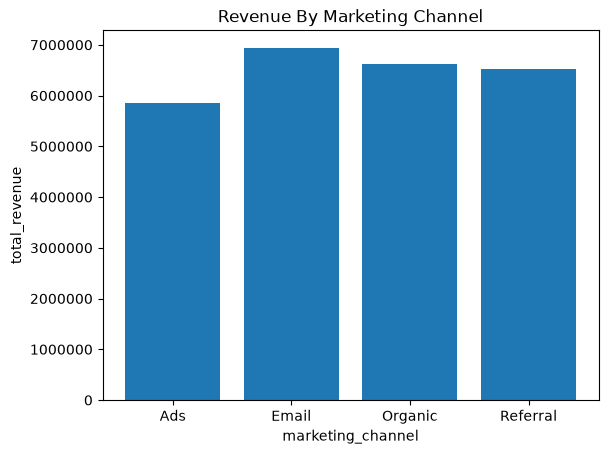

marketing_channel
Ads         5848095.40
Email       6936615.55
Organic     6627841.15
Referral    6529543.65
Name: total_revenue, dtype: float64

In [304]:
rev_m=df.groupby("marketing_channel") ["total_revenue"].sum()
rev_m

plt.bar(rev_m.index,rev_m.values)
plt.title("Revenue By Marketing Channel")
plt.xlabel("marketing_channel")
plt.ylabel("total_revenue")
plt.ticklabel_format(axis='y', style='plain')
plt.savefig("visuals/Revenue By Marketing Channel.png", dpi=100, bbox_inches="tight")


plt.show()
rev_m

In [158]:
observation:- Email marketing generates the highest revenue followed by organic,referral and ads .

Insights:- Company should focous on more investing in Email market and also make more campaign about
            emails. and to investigate why ads has least perfromance and improve it .


**Revenue by city**

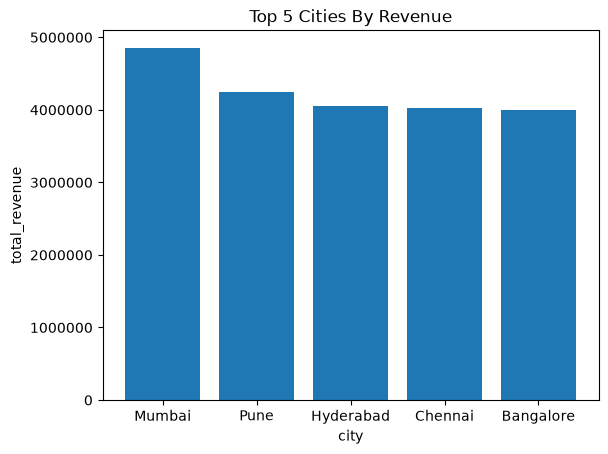

In [306]:
rev_city=pd.pivot_table(
    df,
    index="city",
    values="total_revenue",
    aggfunc="sum"
).sort_values(by="total_revenue",ascending=False).head(5)
rev_city

plt.bar(rev_city.index,rev_city["total_revenue"])
plt.ticklabel_format(axis='y', style='plain')
plt.title("Top 5 Cities By Revenue")
plt.savefig("visuals/Top 5 Cities By Revenue.png", dpi=100, bbox_inches="tight")

plt.xlabel("city")
plt.ylabel("total_revenue")
plt.show()

In [ ]:
Observation:- Mumbai generates the highest total revenue, followed by Pune, Hyderabad, Chennai, and Bangalore.

Insights:- The company should investigate what are the key factors are driving the highest mumbai revenue
           and alongside this stratagies apply to others cities and aslo analyze the performance of other cities.

**Revenue vs Tenure**

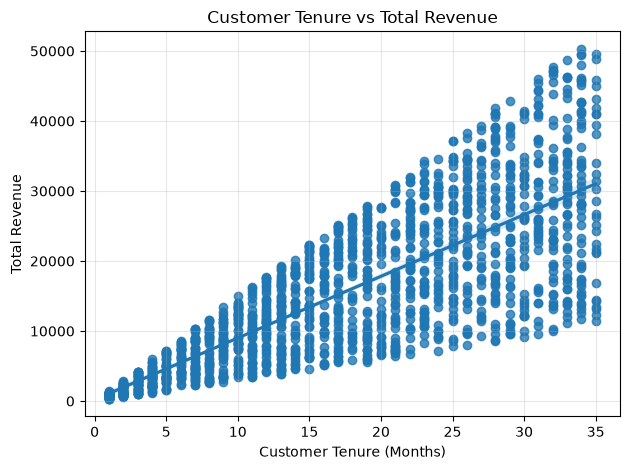

In [307]:
sns.regplot(
    data=df,
    x="tenure_months",
    y="total_revenue")
plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Total Revenue")
plt.title("Customer Tenure vs Total Revenue")
plt.savefig("visuals/Customer Tenure vs Total Revenue.png", dpi=100, bbox_inches="tight")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [205]:
Obseravtion:- Customer with longer tenure generally generate higher revenue, also indicating 
                positive relationship between customer tenure and revenue . regression line id going upward 
                direction.

insights:-  the customer are longer tenure they generate the highest revenuecompany gives them reward,offers
            or different schemes and better customer support  that they can continue forward.
           also focous on customer retainsion

**Average Session Time vs Total Revenue**

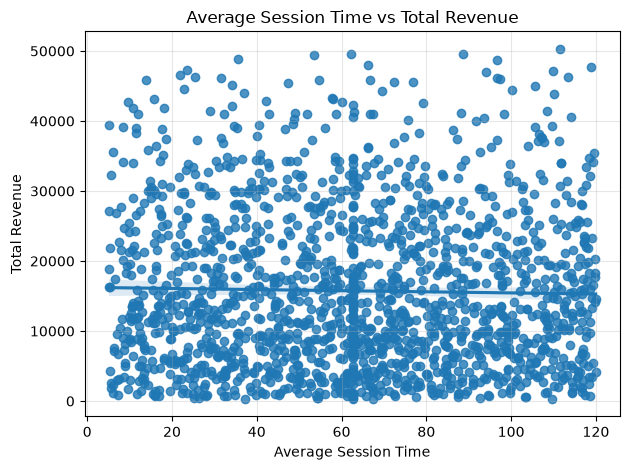

In [308]:
sns.regplot(
    data=df,
    x="avg_session_time",
    y="total_revenue")
plt.xlabel("Average Session Time")
plt.ylabel("Total Revenue")
plt.title("Average Session Time vs Total Revenue")
plt.savefig("visuals/Average Session Time vs Total Revenue.png", dpi=100, bbox_inches="tight")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Signup trend over time**

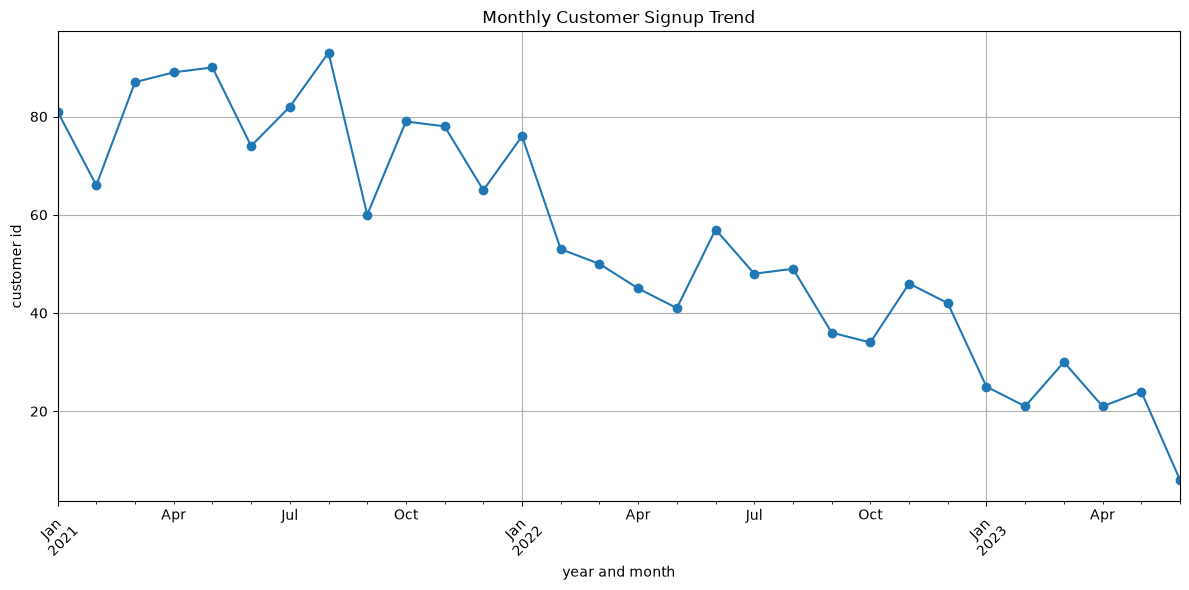

In [309]:


df["signup_period"] = df["signup_date"].dt.to_period("M")

monthly_signups = df.groupby("signup_period")["customer_id"].count()
plt.figure(figsize=(12,6))
monthly_signups.plot(kind="line",marker="o")

plt.title("Monthly Customer Signup Trend")
plt.xlabel("year and month")
plt.ylabel("customer id")
plt.grid(True)
plt.xticks(rotation=45)
plt.savefig("visuals/Monthly Customer Signup Trend.png", dpi=100, bbox_inches="tight")

plt.tight_layout()
plt.show()



In [256]:
print(monthly_signups.max())
print(monthly_signups.min())

93
6


In [ ]:
observation:- Customer signups show an overall decreasing trend over the observed period, shows a few temporary increases. 
             The highest signup count occurs around August 2021.

insights:- the company should know why customer trend line is over time constantly descreasing , the highest no of signup orders are in aug 2021.

**Monthly Revenue Trend**

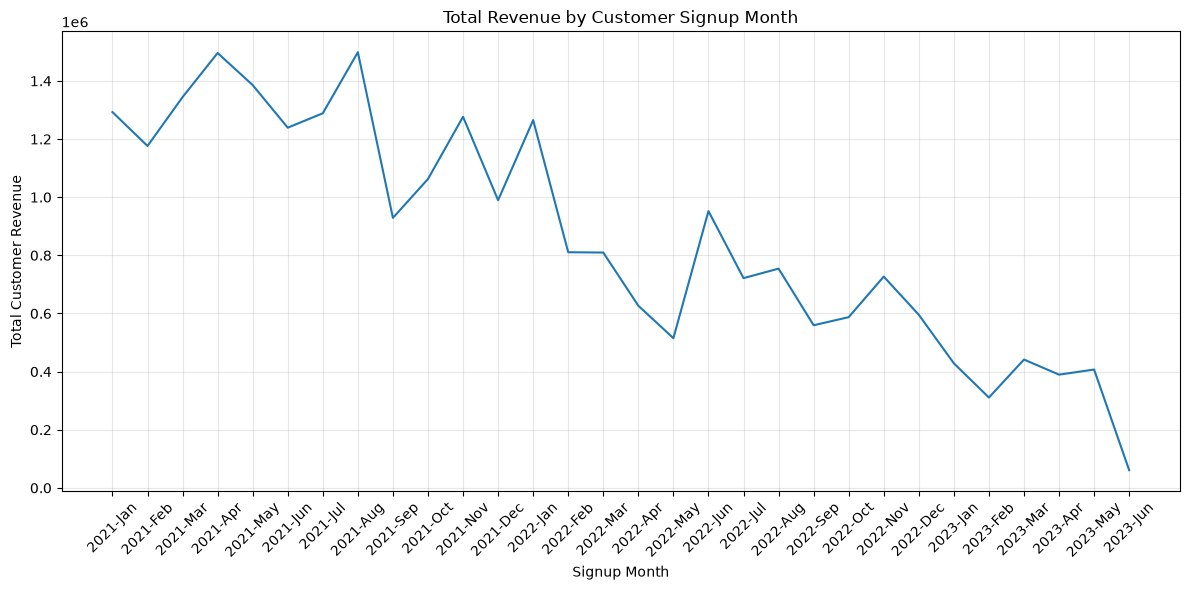

In [310]:


# 
df["signup_period"] = df["signup_date"].dt.to_period("M")

p = pd.pivot_table(
    df,
    index="signup_period",
    values="total_revenue",
    aggfunc="sum"
)
p
plt.figure(figsize=(12,6))

plt.plot(p.index.strftime("%Y-%b"),p.values)
plt.xlabel("Signup Month")
plt.ylabel("Total Customer Revenue")
plt.title("Total Revenue by Customer Signup Month")
plt.savefig("visuals/Total Revenue by Customer Signup Month.png", dpi=100, bbox_inches="tight")

plt.tight_layout
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Clean EDA save file**

In [324]:
df.to_csv("customer_analytics_cleaned.csv", index=False)

In [327]:
!pip install openpyxl

In [331]:
df.to_excel( "customer_analytics_cleaned.xlsx", index=False,engine="openpyxl")  

In [335]:
import os

print(os.path.abspath("customer_analytics_cleaned.xlsx"))
print(os.path.exists("customer_analytics_cleaned.xlsx"))

C:\Users\Saurabh\Subscription_data_project_pandas_matplotlib\customer_analytics_cleaned.xlsx
True
